# Practical implementation: Hierarchical clustering

## Required libraries

### Understanding the libraries

| Library | Purpose |
|---|---|
| `pandas` | Loading and manipulating datasets |
| `numpy` | Numerical calculations |
| `matplotlib` | Creating visualizations |
| `AgglomerativeClustering` | Performing hierarchical clustering |
| `StandardScaler` | Standardizing numerical features |
| `linkage` | Calculating hierarchical cluster linkages |
| `dendrogram` | Visualizing the clustering hierarchy |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

## Load the dataset

In [3]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

print(X.head())
print("Dataset shape:", X.shape)
print(X.describe())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Dataset shape: (150, 4)
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   


**Important**: 

`y` contains the actual flower species labels. 

We do not use them to train the clustering algorithm because clustering is unsupervised. 

They can be used afterwards to help interpret the discovered groups.

## Visualize the Data
```
What does this do?
- plt.subplots() creates a plotting area.
- ax.scatter() creates a scatter plot.
- The first argument represents the X-axis.
- The second argument represents the Y-axis.
- set_xlabel() and set_ylabel() label the axes.
- set_title() gives the graph a title.
- plt.show() displays the graph.
```

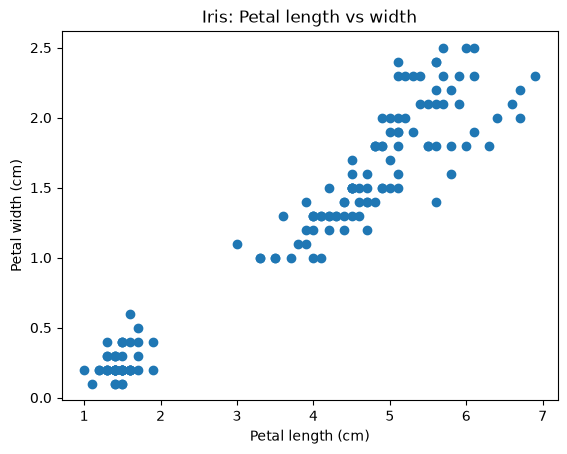

In [4]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"]
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Iris: Petal length vs width")

plt.show()

##### Sepal Length against Sepal Width:

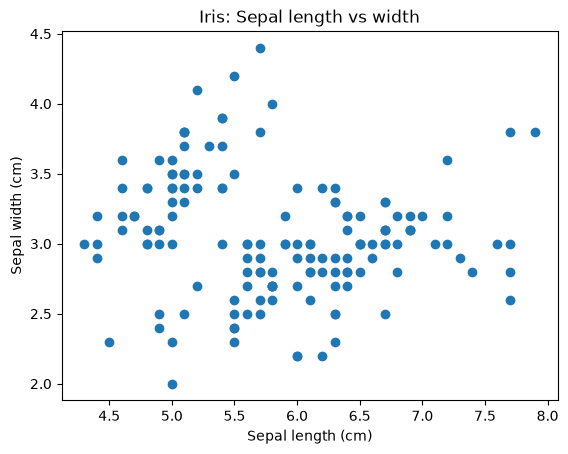

In [5]:
fig, ax = plt.subplots()

ax.scatter(
    X["sepal length (cm)"],
    X["sepal width (cm)"]
)

ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
ax.set_title("Iris: Sepal length vs width")

plt.show()

## Standardize the Features

This is a very important preprocessing step.

Different features may have different scales. Features with larger numerical values or variation can disproportionately influence distance calculations.

Standardization converts features to a comparable scale.

The formula is:
$$
z=\frac{x-\mu}{\sigma}
$$

Where:
- $(x)$ = Original value.
- $(\mu)$ = Mean.
- $(\sigma)$ = Standard deviation.
- $(z)$ = Standardized value.

After standardization, each feature has approximately:
- Mean = 0.
- Standard deviation = 1.

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data:")
print(X.iloc[:2].values)

print("\nStandardized data:")
print(X_scaled[:2])

Original data:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]

Standardized data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]]


**Why is this necessary?**

Imagine a dataset containing:
- Age: 18–60.
- Annual income: 10,000–500,000.
- Number of purchases: 1–20.

Without standardization, income may dominate the distance calculations simply because its numerical scale is much larger.

Standardization helps prevent this problem.

## Create a hierarchical Dendrogram

Starting with complete linkage

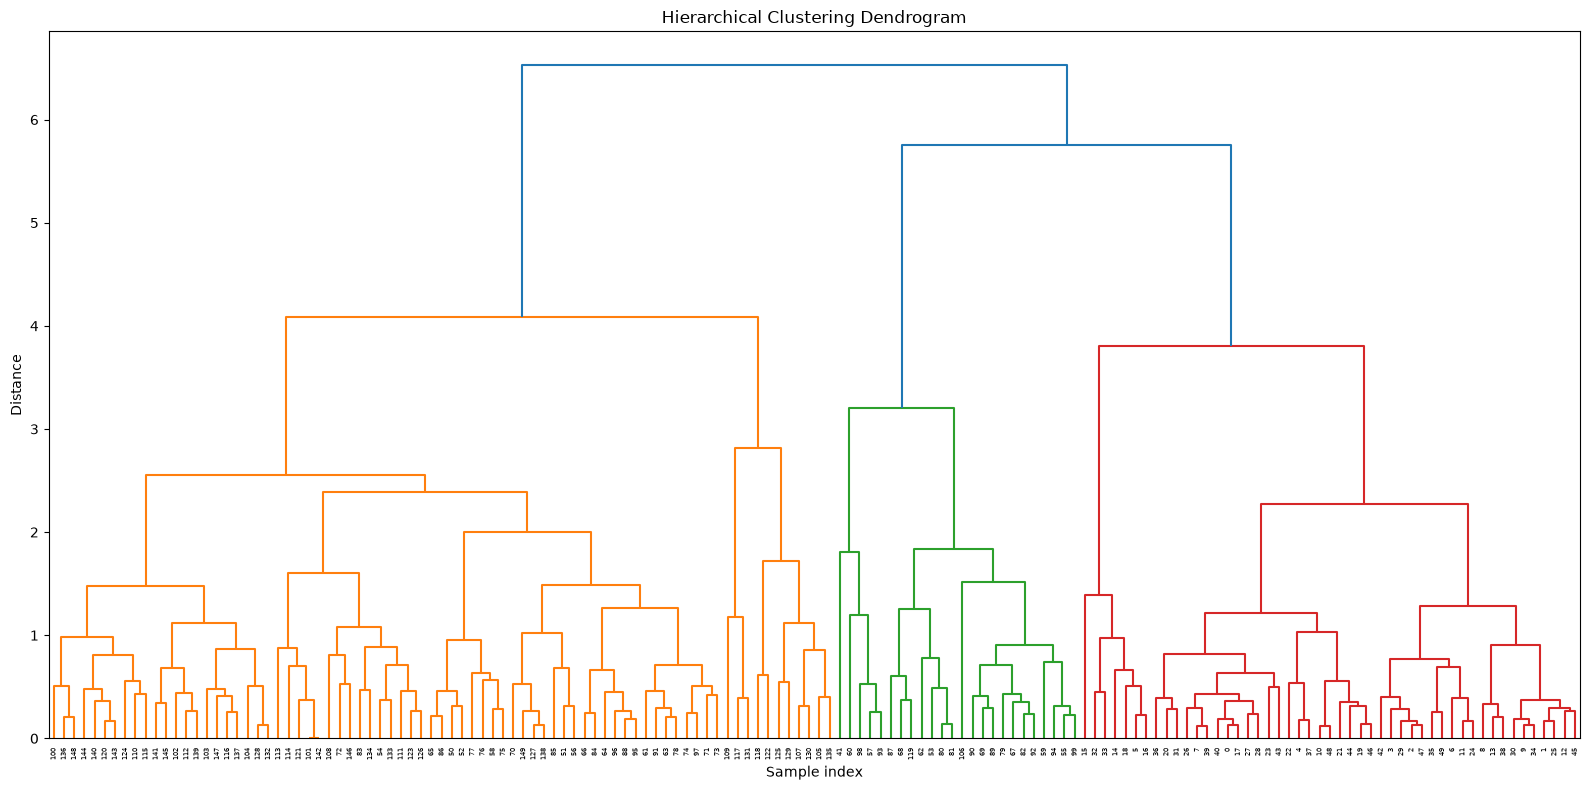

In [10]:
Z = linkage(
    X_scaled,
    method="complete"
)

fig, ax = plt.subplots(figsize=(16, 8))

dendrogram(Z, ax=ax)

ax.set_title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Sample index")
ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()

**Understanding the code:**
```
- linkage() calculates the hierarchical merging structure.
- X_scaled is the standardized dataset.
- method="complete" specifies complete linkage.
- dendrogram() displays the merging structure.
```

## Compare the Linkage Methods

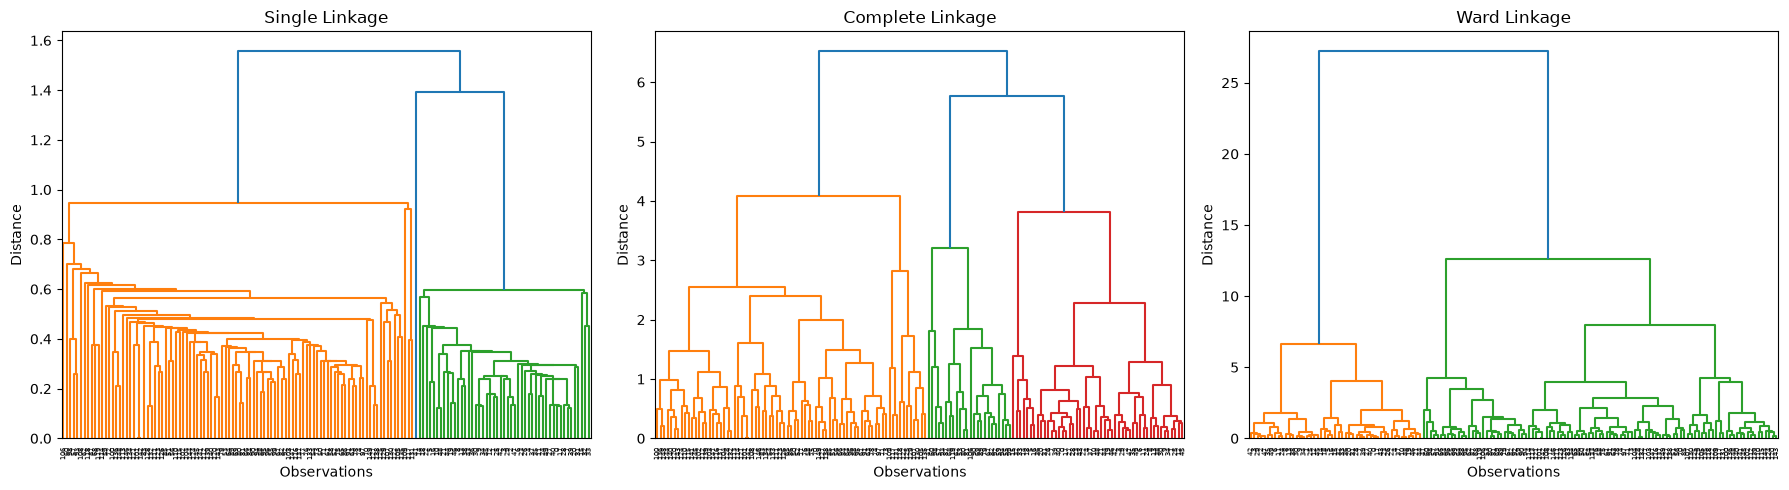

In [18]:
methods = ["single", "complete", "ward"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, method in zip(axes, methods):

    Z = linkage(
        X_scaled,
        method=method
    )

    dendrogram(Z, ax=ax)

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Observations")
    ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()

**How to interpret the results**

- Single linkage may show chaining, where observations are connected gradually.
- Complete linkage tends to produce more compact clusters.
- Ward's method aims to minimize the increase in within-cluster variation.

Note that the dendrogram heights are not directly comparable as identical numerical measures across every linkage method.

## Fit the Hierarchical Clustering Model

A dendrogram helps us understand the structure, but we also need cluster labels for individual observations.

We use `AgglomerativeClustering`.

In [19]:
agg = AgglomerativeClustering(
    n_clusters=3,
    linkage="complete"
)

agg_labels = agg.fit_predict(X_scaled)

print(agg_labels[:10])

[1 1 1 1 1 1 1 1 1 1]


**What happens?**
```
- n_clusters=3 requests three clusters.
- linkage="complete" selects complete linkage.
- fit_predict() performs the clustering and returns the assigned cluster for each observation.
```
Each observation receives a cluster label such as 0, 1 or 2.

Remember that these numbers are simply identifiers. Cluster 2 is not necessarily better than cluster 1.

## Visualize the resulting clusters

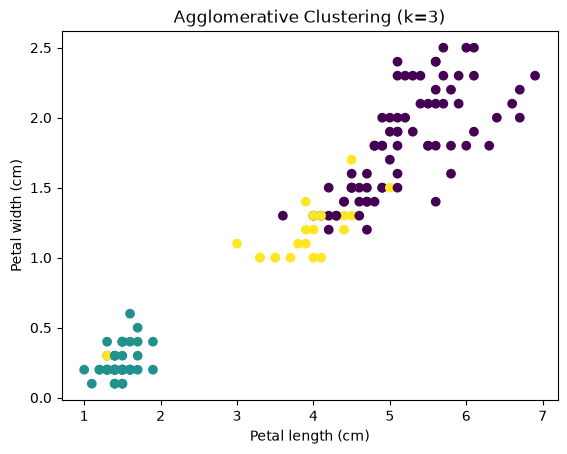

In [20]:
fig, ax = plt.subplots()

ax.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"],
    c=agg_labels
)

ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Agglomerative Clustering (k=3)")

plt.show()

The `c=agg_labels` parameter colours the observations according to their assigned clusters.

**Interpretation**: If the colours form distinct groups, the clustering may have identified meaningful structures in the data.